In [1]:
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
CM = '..//data//21_cmapss_fd001_sample.csv'

df = pd.read_csv(CM)

In [3]:
# ── [개념] 엔진 선택 + 이동평균 rolling().mean() (엔진1·s_2) ─────────────────
# 형식: 시리즈.rolling(window=n).mean() → 앞 n-1개는 값 부족으로 nan.
e1 = df[df['unit_nr'] == 1].reset_index(drop=True)

In [4]:
e1

,unit_nr,time_cycles,setting_1,setting_2,setting_3,s_2,s_3,s_4,s_7,s_11
0,1,1,0.0010,0.0000,100.0,640.69,1585.21,1399.30,554.17,46.931
1,1,2,-0.0003,-0.0002,100.0,641.13,1585.55,1401.18,554.36,46.857
2,1,3,0.0013,0.0000,100.0,641.25,1584.72,1400.84,554.00,47.220
3,1,4,0.0030,0.0001,100.0,641.97,1585.94,1401.26,554.13,47.152
4,1,5,-0.0005,-0.0002,100.0,641.58,1585.72,1401.36,553.87,46.956
...,...,...,...,...,...,...,...,...,...,...
187,1,188,-0.0001,-0.0002,100.0,647.63,1606.39,1418.65,549.65,50.814
188,1,189,-0.0017,-0.0002,100.0,647.05,1608.47,1417.50,550.54,50.915
189,1,190,-0.0030,-0.0001,100.0,646.84,1605.65,1417.31,549.79,50.997
190,1,191,-0.0009,-0.0004,100.0,647.34,1606.83,1418.11,549.72,51.151


In [5]:
# ── [개념] 이동표준편차 rolling().std() + 밴드 (엔진1·s_3) ───────────────────

In [6]:
ma = e1['s_3'].rolling(20).mean()
sd = e1['s_3'].rolling(20).std()

In [7]:
# 실습1 10시 13분

In [8]:
# ── [실습 1] 센서 시계열 그려보기 (엔진2·s_4) ───────────────────────────────

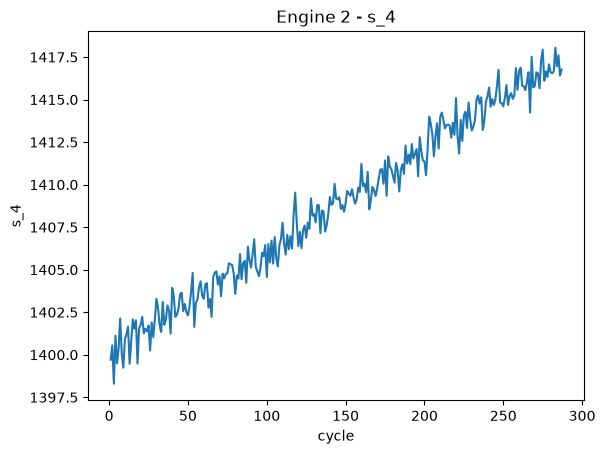

In [9]:
# ── [실습 1] 센서 시계열 그려보기 (엔진2·s_4) ───────────────────────────────
e2 = df[df['unit_nr'] == 2].reset_index(drop=True)
plt.plot(e2['time_cycles'], e2['s_4'])
plt.title('Engine 2 - s_4'); plt.xlabel('cycle'); plt.ylabel('s_4')
plt.show()

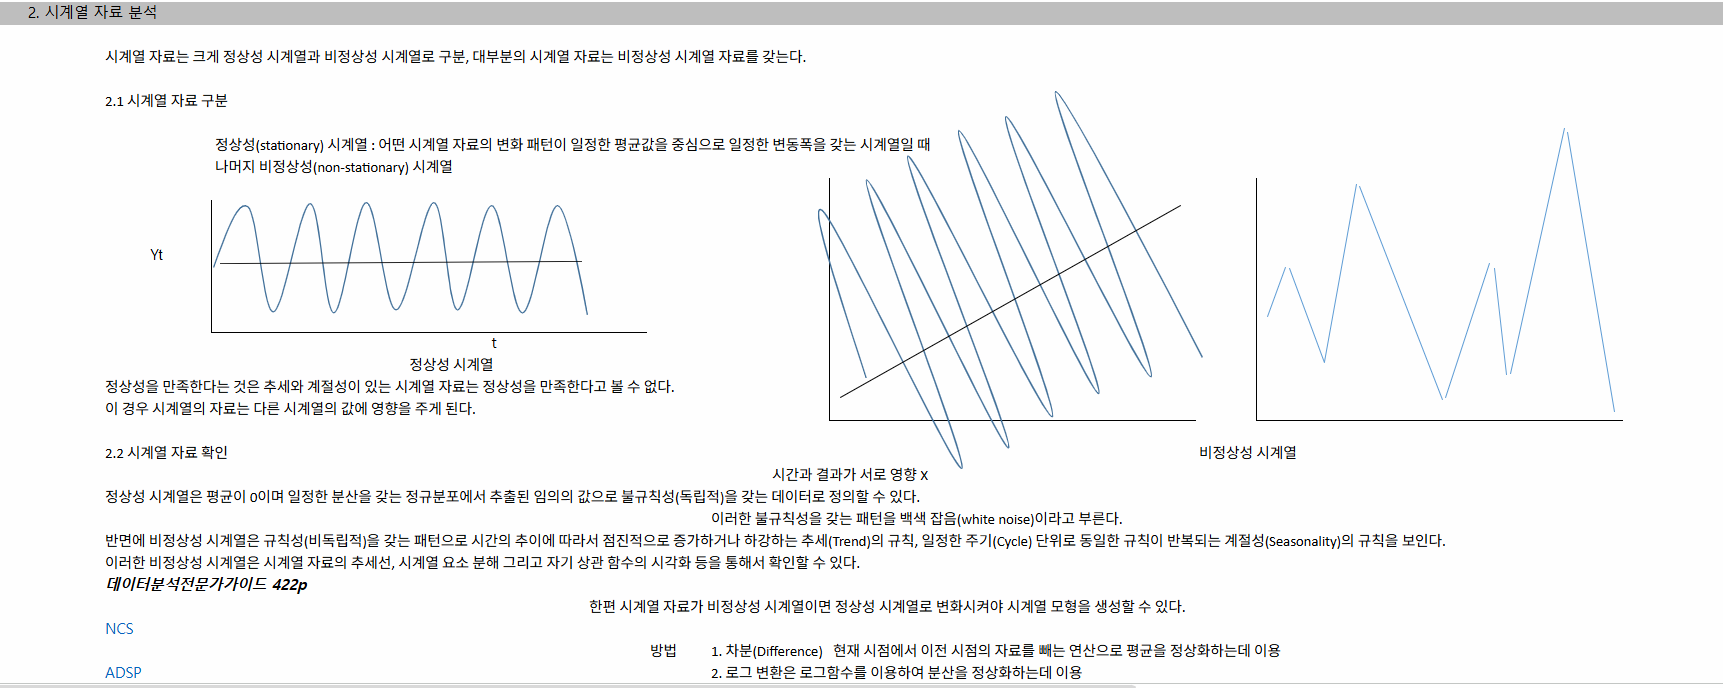

In [11]:
# 실습2 10시 28분 's_4'

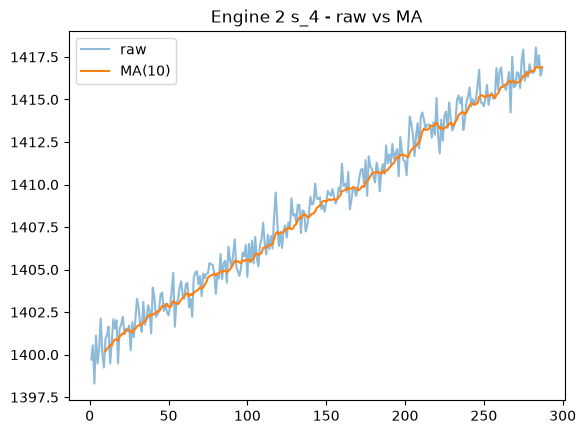

In [12]:
ma10 = e2['s_4'].rolling(window=10).mean()
plt.plot(e2['time_cycles'], e2['s_4'], alpha=0.5, label='raw')
plt.plot(e2['time_cycles'], ma10, label='MA(10)')
plt.title('Engine 2 s_4 - raw vs MA')
plt.legend()
plt.show()


In [13]:
# 실습 3 10시 35분 's_4'

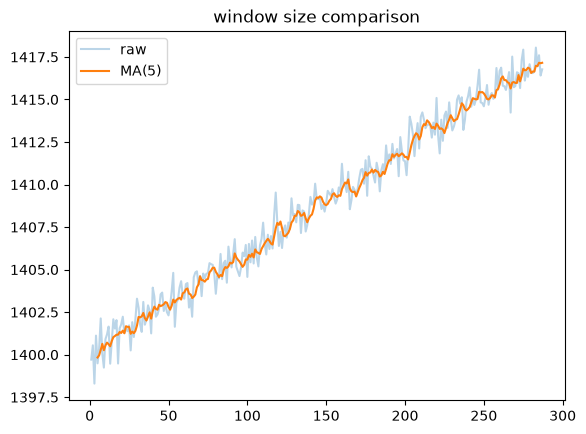

In [14]:
# ── [실습 3] 윈도우 크기 바꿔 비교하기 ──────────────────────────────────────
plt.plot(e2['time_cycles'], e2['s_4'], alpha=0.3, label='raw')
plt.plot(e2['time_cycles'], e2['s_4'].rolling(5).mean(), label=f'MA({5})')
plt.title('window size comparison')
plt.legend()
plt.show()


In [15]:
li = [5, 20, 50]

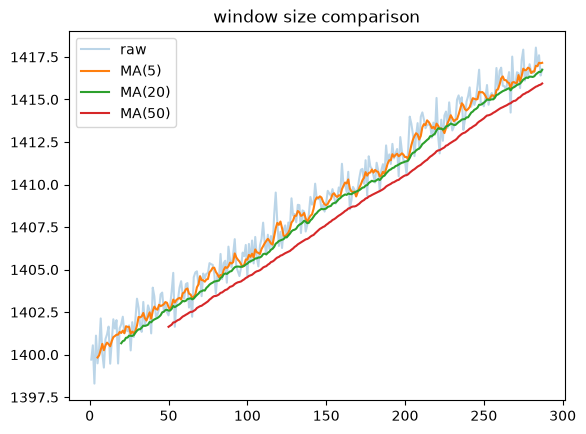

In [17]:
plt.plot(e2['time_cycles'], e2['s_4'], alpha=0.3, label='raw')
for i in li:
    plt.plot(e2['time_cycles'], e2['s_4'].rolling(i).mean(), label=f'MA({i})')
plt.title('window size comparison')
plt.legend()
plt.show()

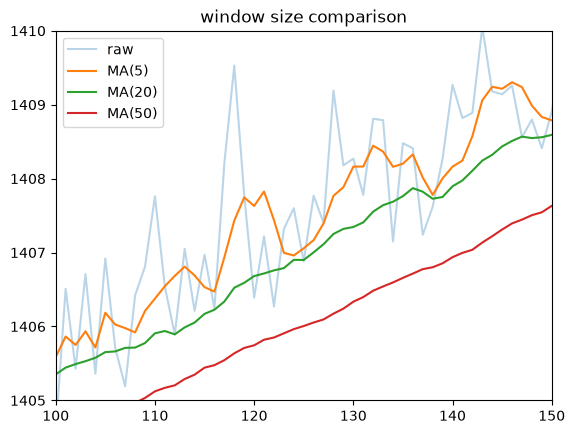

In [21]:
plt.plot(e2['time_cycles'], e2['s_4'], alpha=0.3, label='raw')
for i in li:
    plt.plot(e2['time_cycles'], e2['s_4'].rolling(i).mean(), label=f'MA({i})')
plt.title('window size comparison')
plt.xlim(100,150)
plt.ylim(1405,1410)
plt.legend()
plt.show()

In [19]:
# 실습4 's_4', 's_7', 's_11' 10시 45분

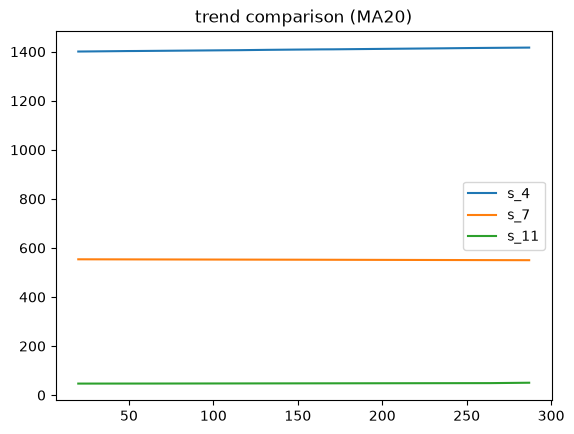

In [22]:
# ── [실습 4] 여러 센서 추세 방향 비교 ───────────────────────────────────────
for col in ['s_4', 's_7', 's_11']:
    plt.plot(e2['time_cycles'], e2[col].rolling(20).mean(), label=col)
plt.title('trend comparison (MA20)'); plt.legend()
plt.show()

In [23]:
" A" if True else "B"

' A'

In [24]:
" A" if False else "B"

'B'

In [25]:
for col in ['s_4', 's_7', 's_11']:
    m = e2[col].rolling(20).mean()
    print(col, '상승' if m.dropna().iloc[-1] > m.dropna().iloc[0] else '하강')   # s_4 상승 / s_7 하강 / s_11 상승

s_4 상승
s_7 하강
s_11 상승


In [27]:
# 실습 5

In [28]:
# ── [실습 5] 이동표준편차로 변동성 구간 찾기 ────────────────────────────────
std20 = e2['s_3'].rolling(window=20).std()

In [29]:
std20

0           NaN
1           NaN
2           NaN
3           NaN
4           NaN
         ...   
282    1.688339
283    1.690562
284    1.764069
285    1.762101
286    1.645253
Name: s_3, Length: 287, dtype: float64

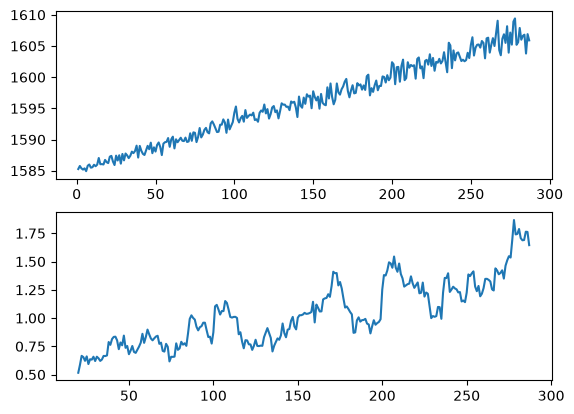

In [30]:
plt.subplot(2,1,1)
plt.plot(e2['time_cycles'], e2['s_3'])
plt.subplot(2,1,2)
plt.plot(e2['time_cycles'], std20)

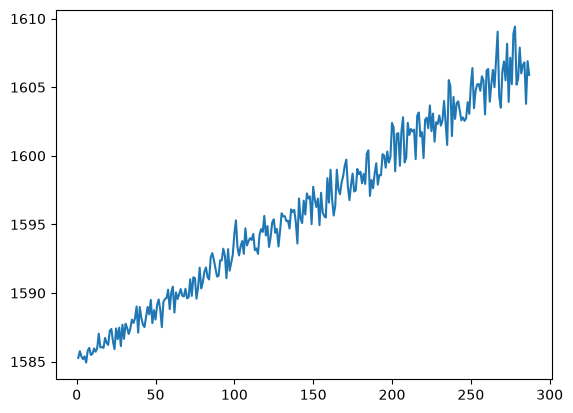

In [31]:
result=plt.plot(e2['time_cycles'], e2['s_3'])

In [32]:
type(result)

list

In [33]:
len(result)

1

In [34]:
result[0]

In [35]:
type(result[0])

matplotlib.lines.Line2D

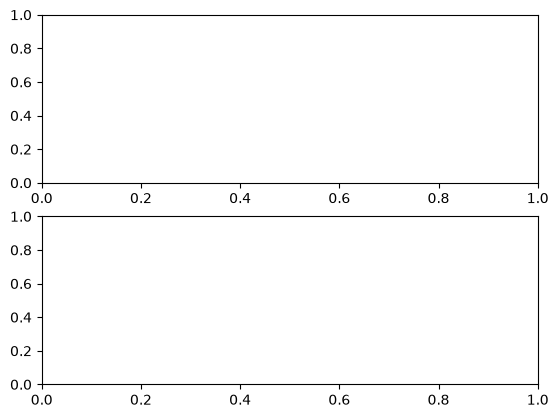

In [36]:
# ── [실습 5] 이동표준편차로 변동성 구간 찾기 ────────────────────────────────
std20 = e2['s_3'].rolling(window=20).std()
fig, (ax1, ax2) = plt.subplots(2, 1)

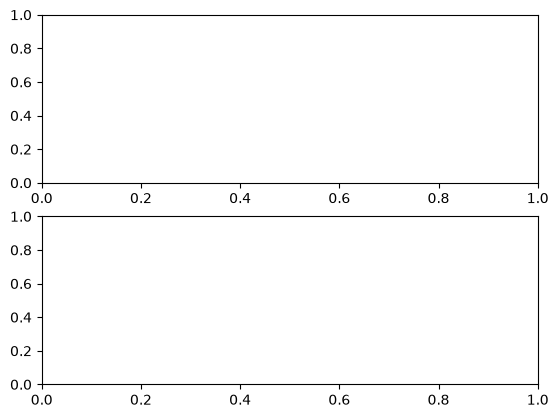

In [37]:
fig

In [38]:
ax1

<Axes: >

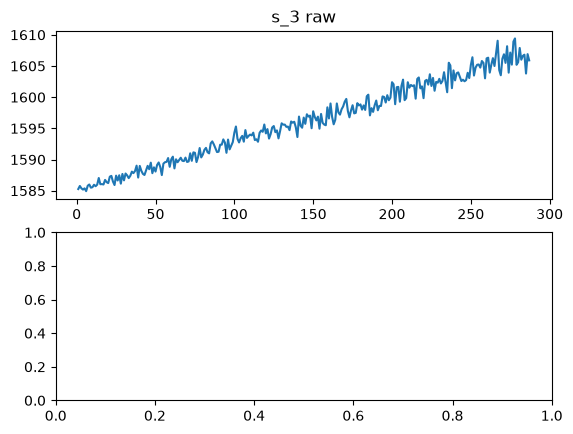

In [40]:
std20 = e2['s_3'].rolling(window=20).std()
fig, (ax1, ax2) = plt.subplots(2, 1)
ax1.plot(e2['time_cycles'], e2['s_3']); ax1.set_title('s_3 raw')
plt.show()

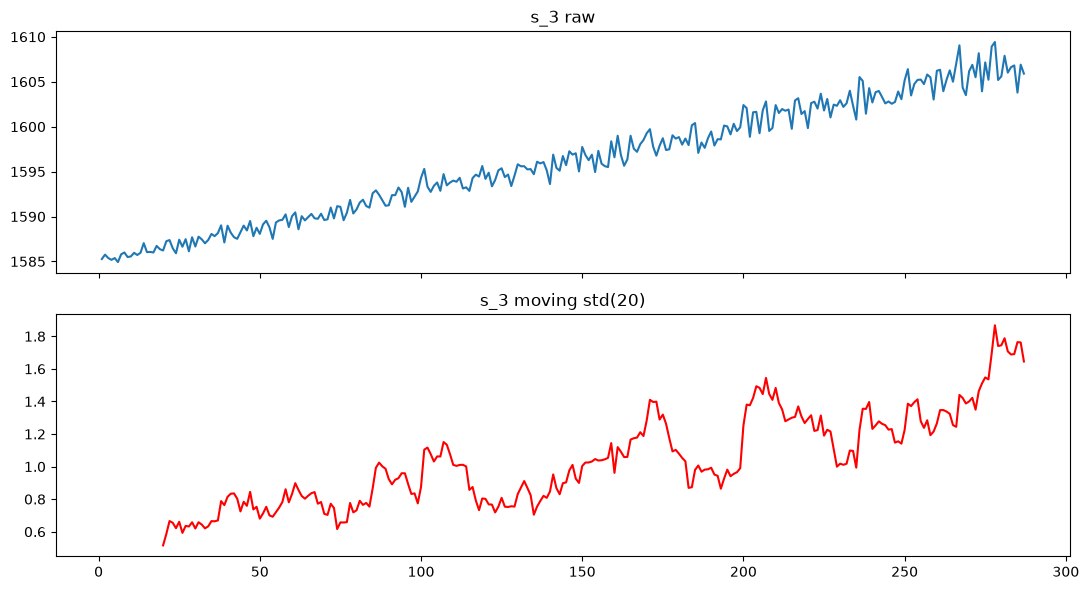

In [41]:
std20 = e2['s_3'].rolling(window=20).std()
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax1.plot(e2['time_cycles'], e2['s_3']); ax1.set_title('s_3 raw')
ax2.plot(e2['time_cycles'], std20, color='red'); ax2.set_title('s_3 moving std(20)')
plt.tight_layout();
plt.show()
# print('std20 후반(idx180):', round(std20.iloc[180], 3))   # 1.053


In [43]:
# std20 = e2['s_3'].rolling(window=20).std()
# fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharey=True)
# ax1.plot(e2['time_cycles'], e2['s_3']); ax1.set_title('s_3 raw')
# ax2.plot(e2['time_cycles'], std20, color='red'); ax2.set_title('s_3 moving std(20)')
# plt.tight_layout();
# plt.show()

In [44]:
# 11시 15분까지 실습 5 정리 후 제출

In [45]:
# ── [실습 6] 평균과 변동성 밴드 함께 그리기 ─────────────────────────────────

In [46]:
ma = e2['s_3'].rolling(20).mean()

In [47]:
ma

0            NaN
1            NaN
2            NaN
3            NaN
4            NaN
         ...    
282    1606.3915
283    1606.4190
284    1606.3585
285    1606.3530
286    1606.1955
Name: s_3, Length: 287, dtype: float64

In [48]:
sd = e2['s_3'].rolling(20).std()

In [49]:
sd

0           NaN
1           NaN
2           NaN
3           NaN
4           NaN
         ...   
282    1.688339
283    1.690562
284    1.764069
285    1.762101
286    1.645253
Name: s_3, Length: 287, dtype: float64

In [53]:
ma - 2*sd,  ma + 2*sd

(0              NaN
 1              NaN
 2              NaN
 3              NaN
 4              NaN
           ...     
 282    1603.014823
 283    1603.037877
 284    1602.830362
 285    1602.828797
 286    1602.904994
 Name: s_3, Length: 287, dtype: float64,
 0              NaN
 1              NaN
 2              NaN
 3              NaN
 4              NaN
           ...     
 282    1609.768177
 283    1609.800123
 284    1609.886638
 285    1609.877203
 286    1609.486006
 Name: s_3, Length: 287, dtype: float64)

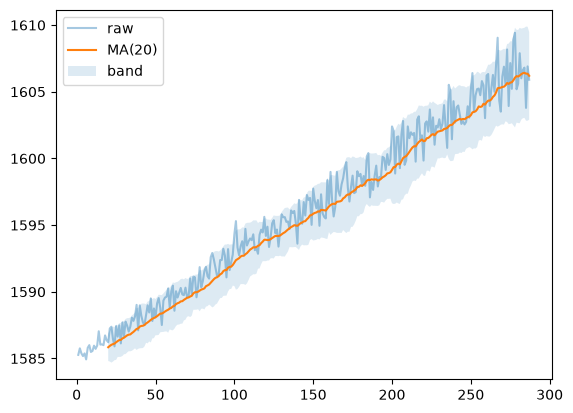

In [50]:
plt.plot(e2['time_cycles'], e2['s_3'], alpha=0.4, label='raw')
plt.plot(e2['time_cycles'], ma, label='MA(20)')
plt.fill_between(e2['time_cycles'], ma - 2*sd, ma + 2*sd, alpha=0.15, label='band')
plt.legend()
plt.show()

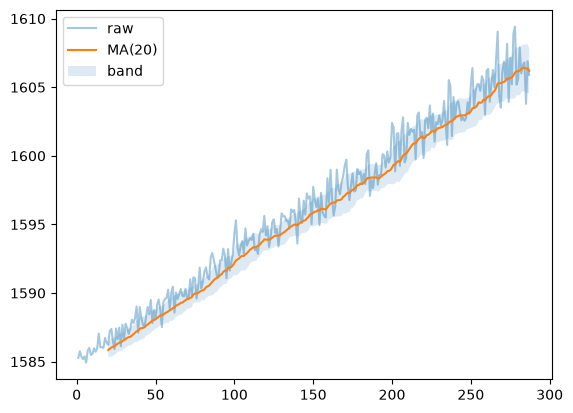

In [51]:
plt.plot(e2['time_cycles'], e2['s_3'], alpha=0.4, label='raw')
plt.plot(e2['time_cycles'], ma, label='MA(20)')
plt.fill_between(e2['time_cycles'], ma - 1*sd, ma + 1*sd, alpha=0.15, label='band')
plt.legend()
plt.show()

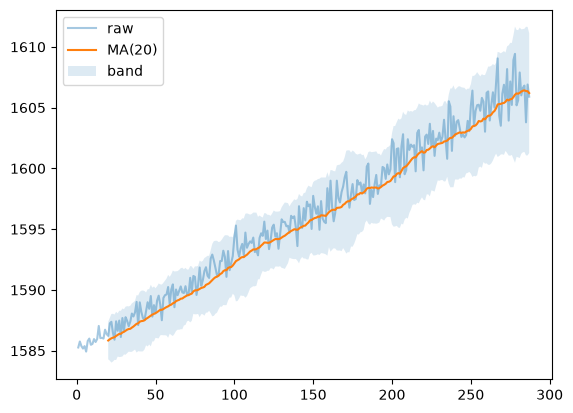

In [52]:
plt.plot(e2['time_cycles'], e2['s_3'], alpha=0.4, label='raw')
plt.plot(e2['time_cycles'], ma, label='MA(20)')
plt.fill_between(e2['time_cycles'], ma - 3*sd, ma + 3*sd, alpha=0.15, label='band')
plt.legend()
plt.show()

In [54]:
# 's_2', 's_3', 's_11'

In [58]:
# 실습 7 11시 38분까지 해석까지 제출

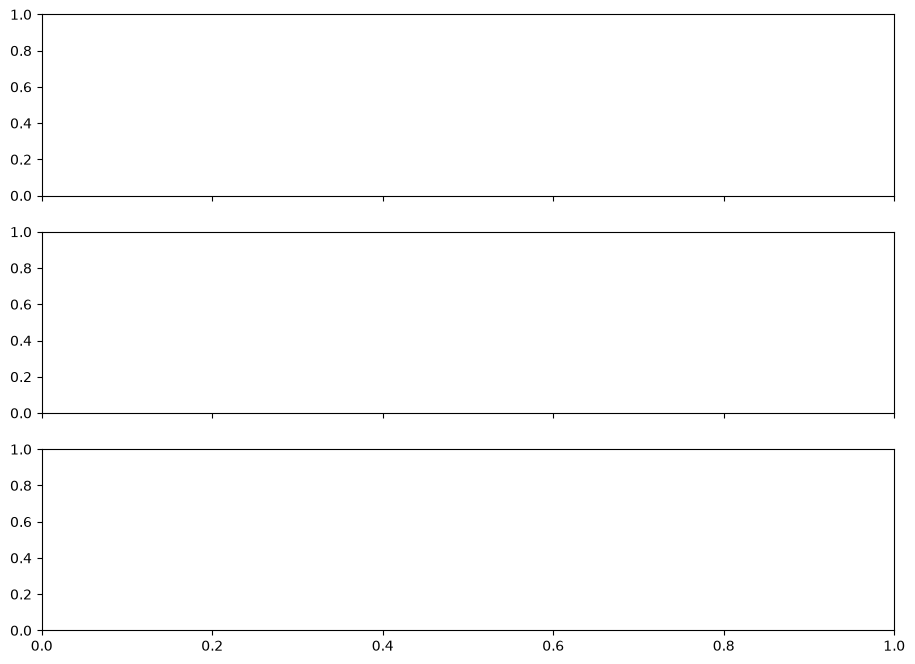

In [59]:
# ── [실습 7] 변동성 패턴 해석 (종합) ────────────────────────────────────────
sensors = ['s_2', 's_3', 's_11']
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

In [60]:
axes

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

In [61]:
for ax, col in zip(axes, sensors):
    print(ax,col)

Axes(0.125,0.653529;0.775x0.226471) s_2
Axes(0.125,0.381765;0.775x0.226471) s_3
Axes(0.125,0.11;0.775x0.226471) s_11


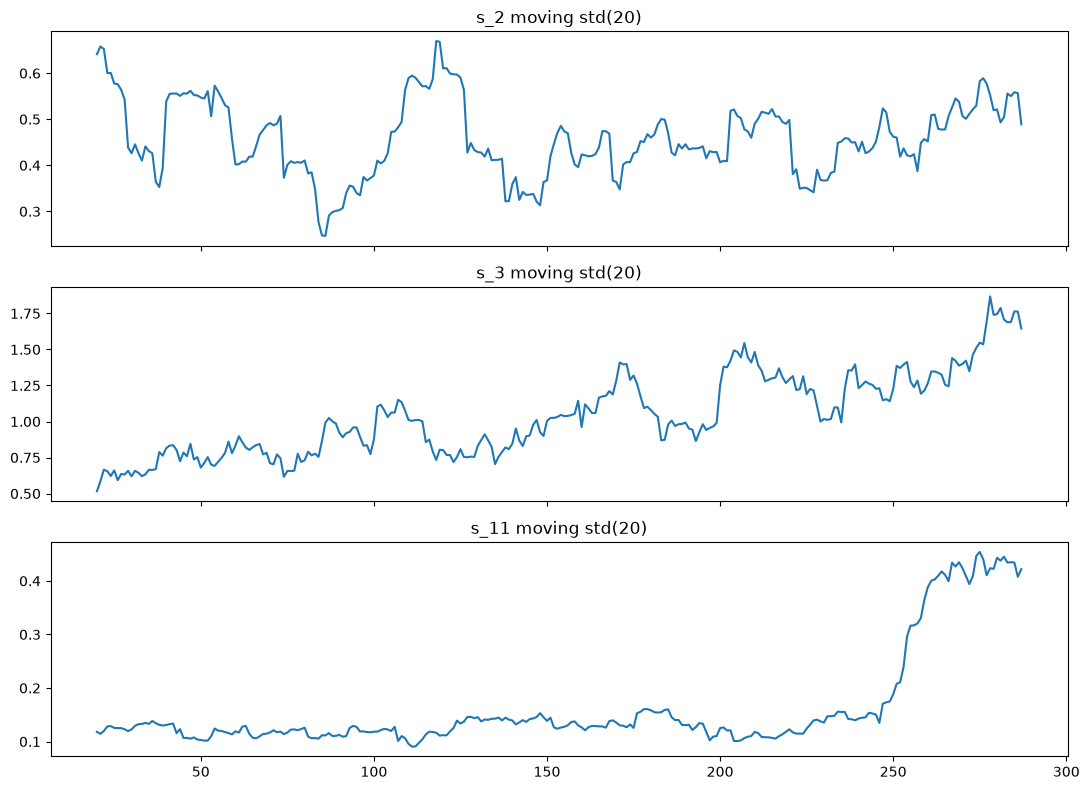

In [62]:
# ── [실습 7] 변동성 패턴 해석 (종합) ────────────────────────────────────────
sensors = ['s_2', 's_3', 's_11']
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, col in zip(axes, sensors):
    ax.plot(e2['time_cycles'], e2[col].rolling(20).std())
    ax.set_title(col + ' moving std(20)')
plt.tight_layout()
plt.show()

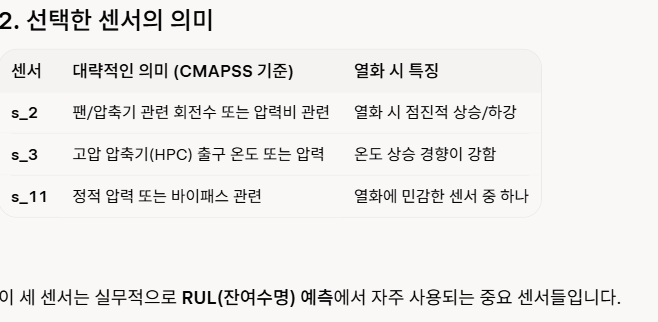